# Archiving Models & Methods

This example demonstrates to {{poptus}} method developers how to use the {{poptus}} archiving facilities in their code.  It also demonstrates how the facility could be used in developing a model as well as how a full application with "analysis" of method results might look.

Please read the User Guide's information about archiving before studying this example.

In [1]:
# Remove input/outputs in rendering

import copy
import functools
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pathlib import Path

plt.style.use("ggplot")

# Always remove file so that the archiver can create the file from
# scratch without asking it to force an overwrite.
FILENAME_H5 = Path.cwd().joinpath("my_example_output.h5")
if FILENAME_H5.is_file():
    os.remove(FILENAME_H5)

## Archiving in the method

Rather than hardcode the full locations of attributes and tables in the archive, we prefer to define the locations relative to the fundamental path constants in ``poptus``.  This is more maintainable since ultimately developers don't care about the fine details of the internal file structure.

In [2]:
import poptus

# Configuration information
THRESHOLD_ATTR = poptus.ARCHIVE_METHOD_GROUP.joinpath("Threshold")
MAX_EVAL_ATTR = poptus.ARCHIVE_METHOD_GROUP.joinpath("MaxEvaluations")
SEED_ATTR = poptus.ARCHIVE_METHOD_GROUP.joinpath("RandomSeed")

# Execution information
START_UTC_ATTR = poptus.ARCHIVE_RESULTS_GROUP.joinpath("StartTime")
END_UTC_ATTR = poptus.ARCHIVE_RESULTS_GROUP.joinpath("EndTime")
N_EVALS_ATTR = poptus.ARCHIVE_RESULTS_GROUP.joinpath("NEvaluations")
FLAG_ATTR = poptus.ARCHIVE_RESULTS_GROUP.joinpath("Flag")

# Evaluation tables
X_TABLE = poptus.ARCHIVE_RESULTS_GROUP.joinpath("X")
F_TABLE = poptus.ARCHIVE_RESULTS_GROUP.joinpath("F")
HF_TABLE = poptus.ARCHIVE_RESULTS_GROUP.joinpath("hF")
SCALE_TABLE = poptus.ARCHIVE_RESULTS_GROUP.joinpath("ScaleFactor")

For development purposes, we first define a class that encapsulates the results of an execution of the method we are developing.  Using the ``read_*`` archiver member functions, we're able to quickly read in attributes and tables.  We choose to return all evaluation tables as pandas DataFrames.

Using different pieces of information in the archive, we're also able to offer to the user a "rich" visualization of the method's progression.

In [3]:
class Result(object):
    def __init__(self, filename):
        super().__init__()

        self.__archiver = poptus.create_archiver(filename, poptus.ARCHIVE_READONLY)

    @property
    def stopping_criteria(self):
        with self.__archiver.open():
            return self.__archiver.read_attribute(THRESHOLD_ATTR)
    
    @property
    def flag(self):
        with self.__archiver.open():
            return self.__archiver.read_attribute(FLAG_ATTR)

    def __load_evaluation_table(self, table_name):
        with self.__archiver.open():
            df = pd.DataFrame(self.__archiver.read_table(table_name))
        df = df.set_index("index", drop=True)
        df.index = df.index.rename("evaluation")
        return df[df.index >= 1]
    
    @property
    def X(self):
        return self.__load_evaluation_table(X_TABLE)

    @property
    def F(self):
        return self.__load_evaluation_table(F_TABLE)

    @property
    def h(self):
        return self.__load_evaluation_table(HF_TABLE)

    @property
    def scale_factor(self):
        return self.__load_evaluation_table(SCALE_TABLE)

    def plot_h(self, fig_num, semilogy=False):
        df = self.h
        
        fig = plt.figure(fig_num)
        fig.suptitle(self.__archiver.filename.name)
        subp = fig.add_subplot(111)
        if semilogy:
            subp.semilogy(df.index, df.hF, "ko-")
        else:
            subp.plot(df.index, df.hF, "ko-")
        subp.axhline(self.stopping_criteria, ls="--", color="red")
        subp.set_xlabel(r"Evaluation $i$")
        subp.set_ylabel(r"$h[\mathbf{F}(\mathbf{x}_i)]$")
        subp.grid(True)
        fig.tight_layout()

We're now able to define the method, which returns a result object.

In [4]:
def poptus_method(model, hfun, configuration, filename):
    max_evaluations = configuration["max_evaluations"]
    stopping_criteria = configuration["threshold"]
    x_0 = configuration["X_0"]
    rand_seed = configuration["seed"]

    # Create the file from scratch and populate with the basic internal structure.
    archiver = poptus.create_archiver(FILENAME_H5, poptus.ARCHIVE_CREATE, force=False)

    # Allow the model to create its Ffun so that it can potentially write
    # data to the same file used by the method.
    Ffun = model.F_function(archiver)

    # ----- ARCHIVE CONFIGURATION & CREATE EVALUATION TABLES
    with archiver.open():
        # -- Model
        # Let the model object archive it and its subcomponents' (e.g., dataset)
        # configuration information if it so chooses.
        model.archive(archiver)

        # Write model information needed by and known by method
        archiver.write_model_spaces(model.parameter_order, model.inner_order)

        # -- Method
        # Create empty tables to store evaluation results
        dtype = [("index", int)] + [(p, float) for p in model.parameter_order]
        archiver.create_evaluation_table(X_TABLE, np.dtype(dtype), max_evaluations)
        dtype = [("index", int)] + [(e, float) for e in model.inner_order]
        archiver.create_evaluation_table(F_TABLE, np.dtype(dtype), max_evaluations)
        dtype = [("index", int), ("hF", float)]
        archiver.create_evaluation_table(HF_TABLE, np.dtype(dtype), max_evaluations)
        dtype = [("index", int), ("scale_factor", float)]
        archiver.create_evaluation_table(SCALE_TABLE, np.dtype(dtype), max_evaluations)

        # Archive provenance on user's behalf
        archiver.write_platform_information()
        archiver.write_software_environment()

        # Method configuration
        archiver.write_attribute(MAX_EVAL_ATTR, max_evaluations)
        archiver.write_attribute(THRESHOLD_ATTR, stopping_criteria)
        archiver.write_attribute(SEED_ATTR, rand_seed)

        # Method execution info
        archiver.write_attribute(START_UTC_ATTR, poptus.now_utc())

    # ----- EXECUTE METHOD
    rng = np.random.default_rng(rand_seed)
    flag = None
    x_i = np.array([x_0[p] for p in model.parameter_order])
    for i in range(1, max_evaluations + 1):
        # Let Ffun open the file for writing if in fact it wants to archive data.
        F_i = Ffun(x_i)
        hF_i = hfun(F_i)
        with archiver.open():
            # Write to file immediately under the assumption that Ffun evaluations
            # could be expensive.
            archiver.append_evaluation(X_TABLE, i, x_i)
            archiver.append_evaluation(F_TABLE, i, F_i)
            archiver.append_evaluation(HF_TABLE, i, [hF_i])

        if hF_i <= stopping_criteria:
            flag = 0
            break

        # Do something with results to determine next x_i and archive
        # results derived in the process.
        factor_i = rng.uniform(low=0.095, high=0.12, size=1)[0]
        x_i *= factor_i
        with archiver.open():
            archiver.append_evaluation(SCALE_TABLE, i, [factor_i])

    if flag is None:
        flag = 1

    # ----- ARCHIVE FINAL RESULTS
    with archiver.open():
        archiver.write_attribute(END_UTC_ATTR, poptus.now_utc())
        archiver.write_attribute(N_EVALS_ATTR, i)
        archiver.write_attribute(FLAG_ATTR, flag)

    return Result(filename)

## Archiving in the model

```{note}
In the future an abstract base class that defines a minimal interface for {{poptus}}-compatible models might be added to the ``poptus`` package.  Actual models instantiated from derived classes could be passed to high-level interfaces of methods so that the methods can interact with the model to archive the model's information.  The high-level methods could also automatically access high-level model data so that the method could simplify the use of the method.

While the model class provided here is in this spirit, it's interface is simple and does not represent a standard {{poptus}} model interface.
```

As with the method, we define the location attributes and an evaluation tables using ``poptus`` location constants.  To demonstrate the creation of custom groups as well as a table that is written once, we will store our model's underlying matrix in a special location.

In [5]:
# Internal structure of Model group
SECRET_GROUP = poptus.ARCHIVE_MODEL_GROUP.joinpath("Secret")

# Configuration information
MODEL_NAME_ATTR = poptus.ARCHIVE_MODEL_GROUP.joinpath("Name")
MODEL_VERSION_ATTR = poptus.ARCHIVE_MODEL_GROUP.joinpath("Version")
MODEL_TABLE = SECRET_GROUP.joinpath("BoringMatrix")

# Evaluation table
INTERMEDIATE_TABLE = poptus.ARCHIVE_MODEL_GROUP.joinpath("Intermediate")

The workhorse of a model is the vector-valued inner function $\Ffun : \R^{\np} \to \R^{\nd}$, whose programmtic implementation we commonly refer to as **Ffun**.  Since these are often expensive to evaluate and can carry out complex computations, model developers might choose to archive important information in the same file as the method results.

In [6]:
def Ffun(x, M, i, archiver):
    # This assumes that the archiver is closed at the time the method 
    # evaluates Ffun.
    #
    # Model developers might want to write to an evaluation table in the
    # model section of the file data derived at each evaluation.  Let's
    # pretend that the following is interesting.
    with archiver.open():
        summary = np.array([np.min(x), np.max(x)])
        archiver.append_evaluation(INTERMEDIATE_TABLE, i[0], summary)

    i[0] += 1

    return M @ x

Our model is parameterized in terms of the underlying linear model as well as other parameters needed to allow **Ffun** to archive internal results.  The following model class constructs a final **Ffun** that only accepts a parameter-space point as input using ``functools.partial``.

This is packaged up with a high-level interface that allows calling code to specify the underlying model and to map meaningful names onto the parameters that define the parameter space ({{ie}} ``parameter_order``) as well as the elements in **Ffun**'s vector output ({{ie}} ``inner_order``).

Finally, this high-level model interface knows how to setup the model section of the archive so that **Ffun** can archive intermediate results at each evaluation and to store important model parameter information alongside method information and results.

In [7]:
class my_model(object):
    def __init__(self, M_df):
        super().__init__()

        self.__inner_order = list(M_df.index)
        self.__parameter_order = list(M_df.columns)
        self.__M = M_df.loc[self.__inner_order, self.__parameter_order].values

    @property
    def parameter_order(self):
        return copy.copy(self.__parameter_order)

    @property
    def inner_order(self):
        return copy.copy(self.__inner_order)

    def F_function(self, archiver):
        return functools.partial(Ffun, M=self.__M, i=[1], archiver=archiver)
 
    def archive(self, archiver):
        # Create groups and evaluation tables
        archiver.create_group(SECRET_GROUP)

        dtype = [("index", int), ("x_min", float), ("x_max", float)]
        archiver.create_evaluation_table(INTERMEDIATE_TABLE, np.dtype(dtype), 1)

        # Store model configuration information
        archiver.write_attribute(MODEL_NAME_ATTR, "Boring")
        archiver.write_attribute(MODEL_VERSION_ATTR, "v1.2.3")
        archiver.write_table(MODEL_TABLE, self.__M)

## The application perspective

There is no hint of the use of the {{poptus}} archiving facility in either the method or the model beyond the fact that the method expects the user to pass in a filename to which information will be written.

Since the model provides information such as the names of its parameters, the archiver uses those names in writing evaluation results to tables.  As a result, the evaluation results we obtain have the correct parameter names in place for us in the DataFrames as opposed to some generic names that a method might otherwise arbitrarily impose.

In [8]:
configuration = {
    "X_0": {"gamma": -1.1, "alpha": 0.3, "beta": 2.2},
    "max_evaluations": 10,
    "threshold": 1.0e-12,
    "seed": 1234
}

M_df = pd.DataFrame(
    data=np.linspace(-1.1, 5.5, 15).reshape((5, 3)),
    index=[f"F_{i}" for i in range(1, 6)],
    columns=["alpha", "beta", "gamma"]
)
model = my_model(M_df)

def hfun(x):
    return np.sum(x**2)

my_result = poptus_method(model, hfun, configuration, FILENAME_H5)
assert my_result.flag == 0
my_result.X

,alpha,beta,gamma
evaluation,,,
1,3.000000e-01,2.200000e+00,-1.100000e+00
2,3.582525e-02,2.627185e-01,-1.313592e-01
3,3.743914e-03,2.745537e-02,-1.372768e-02
4,4.420857e-04,3.241962e-03,-1.620981e-03
5,4.489040e-05,3.291963e-04,-1.645981e-04
6,4.622698e-06,3.389978e-05,-1.694989e-05
7,4.528038e-07,3.320561e-06,-1.660281e-06
8,4.575318e-08,3.355233e-07,-1.677617e-07
9,4.710900e-09,3.454660e-08,-1.727330e-08


Our "rich" visualization combines evaluation results along with the stopping criteria provided to the method.

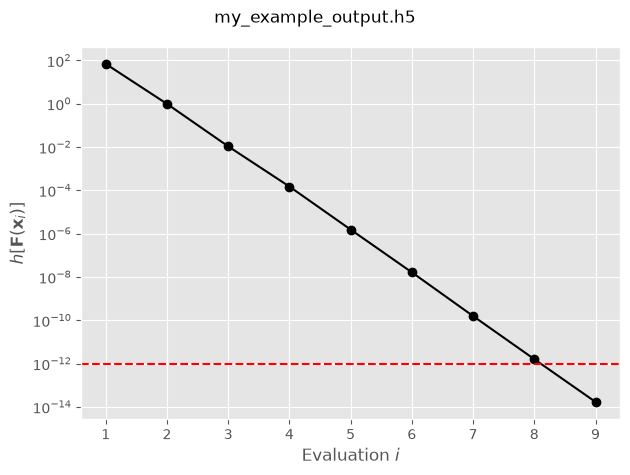

In [9]:
my_result.plot_h(fig_num=1, semilogy=True)